In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
df = pd.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [43]:
df.shape

(1338, 7)

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [45]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [48]:
df.duplicated().sum()

np.int64(0)

In [47]:
df = df.drop_duplicates()

In [49]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [50]:
df.describe(include='object')

,sex,smoker,region
count,1337,1337,1337
unique,2,2,4
top,male,no,southeast
freq,675,1063,364


In [51]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [52]:
print(df['sex'].unique())
print(df['smoker'].unique())
print(df['region'].unique())

['female' 'male']
['yes' 'no']
['southwest' 'southeast' 'northwest' 'northeast']


In [53]:
df = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], dtype=int)


In [54]:
df.head()

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,1,0,0,1,0,0,0,1
1,18,33.770,1,1725.55230,0,1,1,0,0,0,1,0
2,28,33.000,3,4449.46200,0,1,1,0,0,0,1,0
3,33,22.705,0,21984.47061,0,1,1,0,0,1,0,0
4,32,28.880,0,3866.85520,0,1,1,0,0,1,0,0


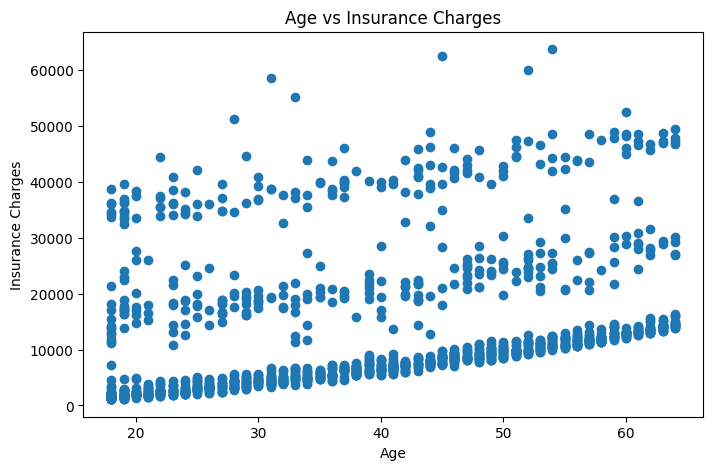

In [55]:
plt.figure(figsize=(8, 5))

plt.scatter(df['age'], df['charges'])

plt.xlabel('Age')
plt.ylabel('Insurance Charges')
plt.title('Age vs Insurance Charges')

plt.show()

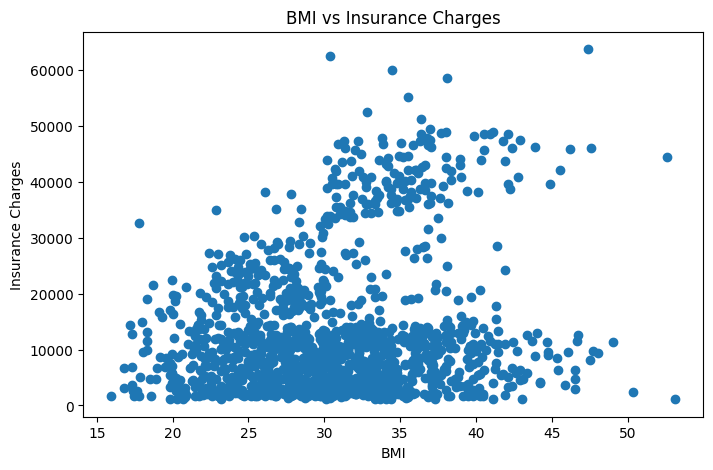

In [56]:
plt.figure(figsize=(8, 5))

plt.scatter(df['bmi'], df['charges'])

plt.xlabel('BMI')
plt.ylabel('Insurance Charges')
plt.title('BMI vs Insurance Charges')

plt.show()

In [57]:
X = df.drop('charges', axis=1)

y = df['charges']

In [58]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1069, 11)
X_test shape: (268, 11)
y_train shape: (1069,)
y_test shape: (268,)


In [31]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [59]:
y_pred = model.predict(X_test)

In [60]:
print(y_pred[:5])

[ 8143.69388412  5737.11568259 14369.31487618 31745.51363586
  8962.38665706]


In [61]:
comparison = pd.DataFrame({
    'Actual Charges': y_test.values,
    'Predicted Charges': y_pred
})

comparison.head()

,Actual Charges,Predicted Charges
0,8688.85885,8143.693884
1,5708.86700,5737.115683
2,11436.73815,14369.314876
3,38746.35510,31745.513636
4,4463.20510,8962.386657


In [62]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)

print("MSE:", mse)

MSE: 35478020.67523559


In [63]:
import numpy as np

rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 5956.342894363587


In [64]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 4177.045561036319


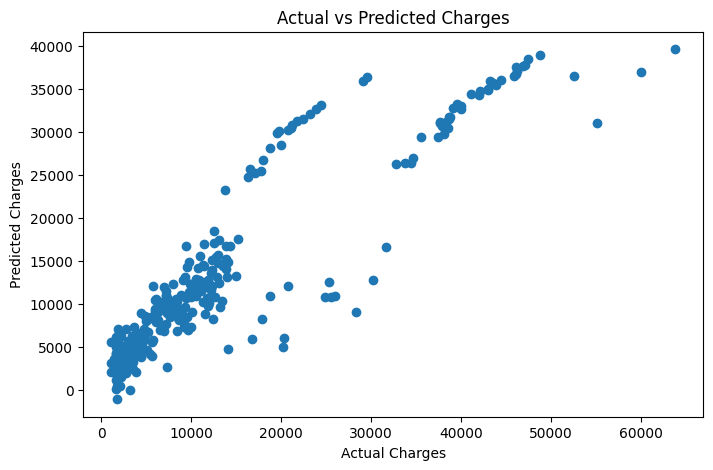

In [65]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Charges')

plt.show()

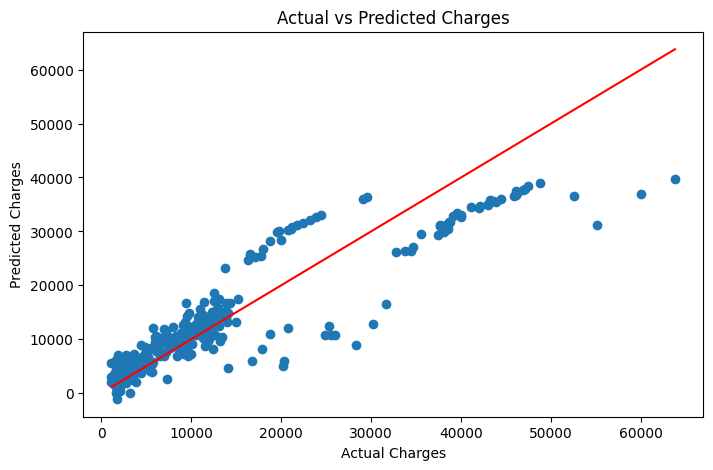

In [66]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Charges')

plt.show()

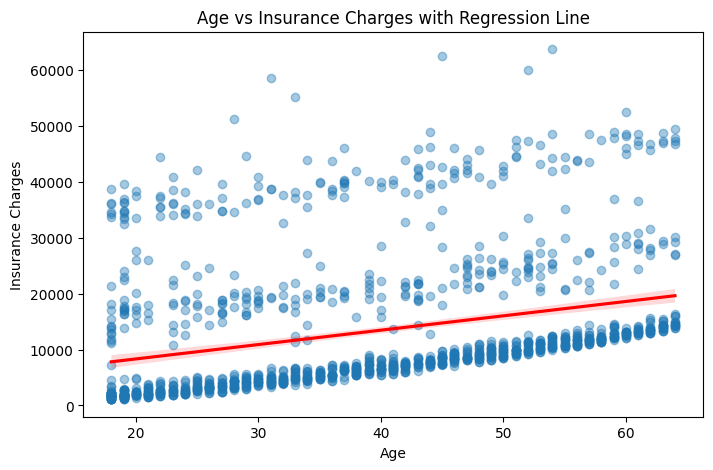

In [67]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x='age',
    y='charges',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.xlabel('Age')
plt.ylabel('Insurance Charges')
plt.title('Age vs Insurance Charges with Regression Line')

plt.show()

In [68]:
smoker_comparison = df.groupby('smoker_yes')['charges'].mean()

print(smoker_comparison)

smoker_yes
0     8440.660307
1    32050.231832
Name: charges, dtype: float64


In [69]:
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred,
    'smoker_yes': X_test['smoker_yes'].values
})

results['Absolute Error'] = abs(
    results['Actual'] - results['Predicted']
)

print(results.groupby('smoker_yes')['Absolute Error'].mean())

smoker_yes
0    2770.268367
1    9053.873165
Name: Absolute Error, dtype: float64


In [70]:

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Select the features we want to improve
X_train_poly = X_train.copy()
X_test_poly = X_test.copy()

# Add polynomial features for age and BMI
poly = PolynomialFeatures(degree=2, include_bias=False)

age_bmi_train = poly.fit_transform(X_train[['age', 'bmi']])
age_bmi_test = poly.transform(X_test[['age', 'bmi']])

# Replace the original age and BMI columns
X_train_poly = X_train_poly.drop(columns=['age', 'bmi'])
X_test_poly = X_test_poly.drop(columns=['age', 'bmi'])

# Add the new polynomial features
poly_columns = poly.get_feature_names_out(['age', 'bmi'])

X_train_poly[poly_columns] = age_bmi_train
X_test_poly[poly_columns] = age_bmi_test

# Train the improved model
improved_model = LinearRegression()
improved_model.fit(X_train_poly, y_train)

# Make predictions
improved_pred = improved_model.predict(X_test_poly)

# Evaluate the improved model
print("Original MAE:", mean_absolute_error(y_test, y_pred))
print("Improved MAE:", mean_absolute_error(y_test, improved_pred))

print("Original RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Improved RMSE:", np.sqrt(mean_squared_error(y_test, improved_pred)))


Original MAE: 4177.045561036319
Improved MAE: 4378.541560215564
Original RMSE: 5956.342894363587
Improved RMSE: 6079.418678287209


In [71]:

# Model Improvement Experiment:
# The original Linear Regression model achieved:
# MAE: 4177.05
# RMSE: 5956.34
#
# To improve the model, we experimented with Polynomial Features
# for the age and BMI features (degree=2).
# However, the improved model achieved:
# MAE: 4378.54
# RMSE: 6079.42
#
# Since both MAE and RMSE increased, the new model performed
# worse than the original model.
# Therefore, we decided to keep the original Linear Regression
# model as our final model because it achieved lower prediction errors.
